# Self-study - a liver biopsy, measured by hand

A pathologist looks at a thin slice of liver under a microscope and writes a report. Two of the
numbers in it:

- **how crowded the nuclei are** - many nuclei in scar tissue means inflammation;
- **how much of the liver is fat** (steatosis) - a liver is called fatty when fat sits in at
  least 5% of its cells.

In this notebook you measure both with **no learning at all**: [48]'s tools and the HSV colour
space from [33] and HW1b. The measurement is the excuse. What you should leave with is five
ideas:

1. **Hue is "which colour", separate from "how bright".**
2. **Erosion and dilation are a min and a max over a window** - together they clean a mask.
3. **Connected components turn pixels into objects** - and without labels nobody can score the
   count.
4. **A threshold is a line drawn on a histogram** - where you draw it decides how fragile the
   answer is.
5. **Hand-tuned rules break when conditions shift** - even a shift you can barely see.

| Part | What you do | Idea |
|---|---|---|
| 1 | meet the two slides; what [48]'s edge detector sees | |
| 2 | colour: RGB fails, hue works - and why | 1 |
| 3 | build the nuclei mask, one condition at a time | 1, 2 |
| 4 | count the nuclei, and check against your own count | 3 |
| 5 | where did the thresholds come from? drive them yourself | 4 |
| 6 | slide B: how much of the liver is fat? | 1, 3 |
| 7 | the honesty test: the same slide, a different scanner | 5 |
| bonus | a kernel shaped like a nucleus | |

## How to use this notebook

**It comes with every output already in it**, so each answer sits right under its question.
To get the most out of it, **clear all outputs first** ("Clear all outputs", in the Edit menu of
Jupyter and of [Colab](https://colab.research.google.com/github/HaykTarkhanyan/python_math_ml_course/blob/main/ml/12_cnn/liver_biopsy_solution.ipynb)) and run the cells one
at a time as you read.

- **Predict** prompts ask you to commit to a guess *before* running the next cell. Write it
  down - on paper is fine. The point is to be surprised (or not) by something you said in
  advance, not to nod along after the fact.
- **Your turn** - three short exercises. Write your answer in the first cell (it tells you
  whether you got it right), and only then read the solution cell under it.
- Each part ends with a **Remember** line and two or three **Check yourself** questions; the
  answers open with a click.
- Part 5 has **sliders**: they need a live kernel (Jupyter or Colab); a static preview such as
  GitHub shows them blank.

**Time:** about 1.5 hours to work through. The code itself runs in about a minute on a laptop
CPU (measured over three runs: 40-85 s for Parts 1-7, ~12 s for the bonus, plus the kernel
start). Plotting cells take 1-4 s each; slower cells say so in their first line.

**Before you start**, you should have seen:

- [33] Color Spaces - what HSV is ([PDF](https://github.com/HaykTarkhanyan/python_math_ml_course/blob/main/ml/09_clustering/33_color_spaces.pdf));
- [48] CNN Foundations - convolution, Sobel, the slides "Dilation and erosion, by hand" and
  "Template matching" ([PDF](https://github.com/HaykTarkhanyan/python_math_ml_course/blob/main/ml/12_cnn/48_cnn_foundations.pdf));
- HW1b - the convolution engine reused below ([notebook](https://github.com/HaykTarkhanyan/python_math_ml_course/blob/main/ml/12_cnn/HW1b_photoshop_solution.ipynb)).

### The biology words, in one table

You need no biology beyond this:

| word | what it means |
|---|---|
| biopsy | a small piece of tissue taken out to look at under a microscope |
| stain | a dye that binds to certain molecules and colours them |
| hepatocyte | the main cell of the liver |
| nucleus (plural: nuclei) | the part of a cell that holds its DNA |
| chromatin | the DNA inside a nucleus, packed with proteins: packed tight it looks dark, packed loosely it looks pale |
| cytoplasm | everything in a cell outside the nucleus |
| collagen | the protein scar tissue is made of |
| fibrosis, cirrhosis | scarring of the liver; cirrhosis is the advanced stage |
| steatosis | fat building up inside liver cells - a "fatty liver" |

## Setup

Loading and plotting helpers. Two of them draw a mask **on top of the tissue** (a tint, an
outline): comparing a mask with the tissue in one picture is far easier than comparing a
black-and-white mask with the tissue next to it. `check` grades the exercises.

In [1]:
# ~10 s the first time (imports)
import time
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.colors import ListedColormap, hsv_to_rgb, rgb_to_hsv
from PIL import Image
from scipy import ndimage

T0 = time.perf_counter()
SEED = 509
BLUE, RED, ORANGE = "#0033A0", "#D90012", "#F2A800"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["image.cmap"] = "gray"

RAW = "https://raw.githubusercontent.com/HaykTarkhanyan/python_math_ml_course/main/ml/12_cnn/"


def load_image(relpath):
    # local checkout first; on Colab download once and cache. Raises if both fail.
    local = Path(relpath)
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        req = Request(RAW + relpath, headers={"User-Agent": "python-math-ml-course/biopsy"})
        with urlopen(req, timeout=60) as r:
            local.write_bytes(r.read())
        print(f"downloaded {relpath}")
    return np.asarray(Image.open(local).convert("RGB"), dtype=float) / 255.0


def show(images, titles, ncols=None, size=3.0, suptitle=None):
    n = len(images)
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 1.14 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(np.clip(np.asarray(im, float), 0, 1))
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=1.01)
    fig.tight_layout()
    plt.show()


def tint(img, mask, colour=(0.1, 1.0, 0.2), alpha=0.6):
    # paint the mask's pixels over the image
    out = np.array(img, float)
    out[mask] = (1 - alpha) * out[mask] + alpha * np.asarray(colour)
    return out


def outline(ax, img, mask, colour="lime", title=""):
    # draw the mask's border on top of the image
    ax.imshow(img, interpolation="nearest")
    if mask.any():
        ax.contour(mask, levels=[0.5], colors=colour, linewidths=1.3)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def hue_hist(ax, hue_deg, lo, hi, step=2):
    # a hue histogram whose bars are painted in their own hue
    edges = np.arange(lo, hi + step, step)
    counts, _ = np.histogram(hue_deg, bins=edges)
    centres = (edges[:-1] + edges[1:]) / 2
    hsv = np.stack([(centres % 360) / 360, np.full(len(centres), 0.6), np.full(len(centres), 0.85)], axis=1)
    ax.bar(centres, counts, width=step, color=hsv_to_rgb(hsv))
    ax.set_xlabel("hue (degrees)")
    ax.set_yticks([])


def check(name, yours, expected, tol):
    # grades an exercise: None means "not answered yet"
    if yours is None:
        print(f"{name}: not answered yet - replace the None above")
    elif abs(yours - expected) <= tol:
        print(f"{name}: {yours:.1f} - correct")
    else:
        print(f"{name}: {yours:.1f} - not quite, expected about {expected:.1f}")


# brightness V is max(R, G, B), so it only takes the values k/255: bin edges halfway between
# them, two levels per bin, keep the histograms free of empty-bin stripes
V_BINS = (np.arange(1, 258, 2) - 0.5) / 255

In [2]:
def to_gray(rgb):
    return rgb @ np.array([0.299, 0.587, 0.114])


def convolve2d_fast(img, kernel):
    # HW1b's tap loop: 'same' size output, edge padding, stride 1
    img = np.asarray(img, float)
    kernel = np.asarray(kernel, float)
    kh, kw = kernel.shape
    p = np.pad(img, ((kh // 2, kh // 2), (kw // 2, kw // 2)), mode="edge")
    out = np.zeros_like(img)
    H, W = img.shape
    for i in range(kh):
        for j in range(kw):
            if kernel[i, j]:
                out += kernel[i, j] * p[i:i + H, j:j + W]
    return out


def gaussian_blur(img, sigma, truncate=3.0):
    # separable: a row pass, then a column pass (HW1b Task 1.3)
    r = int(truncate * sigma)
    g = np.exp(-np.arange(-r, r + 1) ** 2 / (2 * sigma ** 2))
    g /= g.sum()
    return convolve2d_fast(convolve2d_fast(img, g[None, :]), g[:, None])


SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
SOBEL_Y = SOBEL_X.T

# Part 1 - the two slides

| | stain | what is in it |
|---|---|---|
| **A** | **H&E** (haematoxylin and eosin) | cirrhosis from alcohol. Pink cytoplasm, purple nuclei, magenta red blood cells, white channels, a band of scar running diagonally |
| **B** | **Masson trichrome** | fatty liver disease. Red liver cells, **green** scar (collagen), white round holes where fat was |

H&E is pathology's default stain, and it works by chemistry:

- **haematoxylin** binds DNA, so **nuclei turn blue-purple**;
- **eosin** binds proteins, so **cytoplasm turns pink**.

That colour split is the signal everything below depends on.

slide A (H&E)       (1047, 1400, 3)
slide B (trichrome) (1041, 1400, 3)


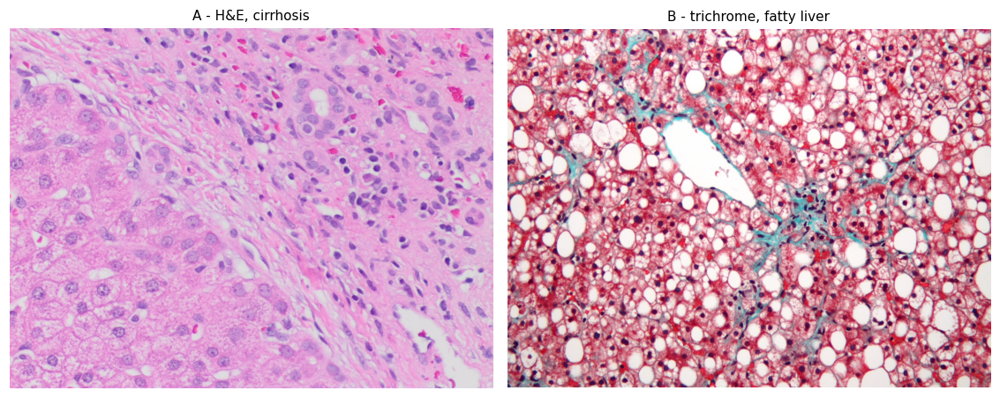

In [3]:
# ~7 s (on Colab the first run also downloads the two images, ~1 MB)
he = load_image("data/liver_he_cirrhosis.jpg")
tri = load_image("data/liver_trichrome_nafld.jpg")
print("slide A (H&E)      ", he.shape)
print("slide B (trichrome)", tri.shape)
show([he, tri], ["A - H&E, cirrhosis", "B - trichrome, fatty liver"], ncols=2, size=5.2)

We work on a 600x600 crop of each: big enough to hold plenty of nuclei, small enough that every
cell below runs in seconds.

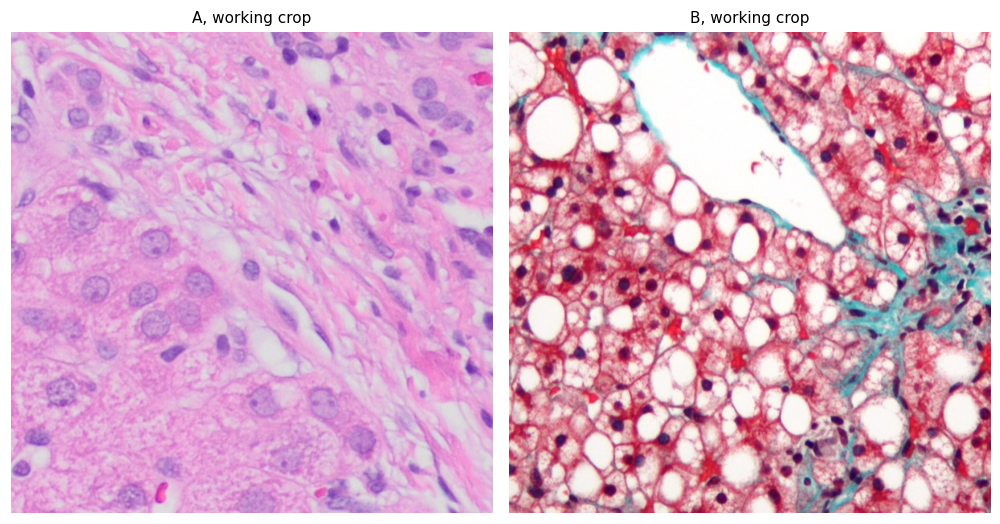

In [4]:
HE = he[300:900, 350:950]
TRI = tri[250:850, 300:900]
show([HE, TRI], ["A, working crop", "B, working crop"], ncols=2, size=4.6)

### What [48]'s edge detector sees

Before colour, try the tool from [48]: a light blur, then Sobel X and Sobel Y, combined into the
gradient magnitude.

**Predict:** will the nuclei stand out from everything else in the edge map?

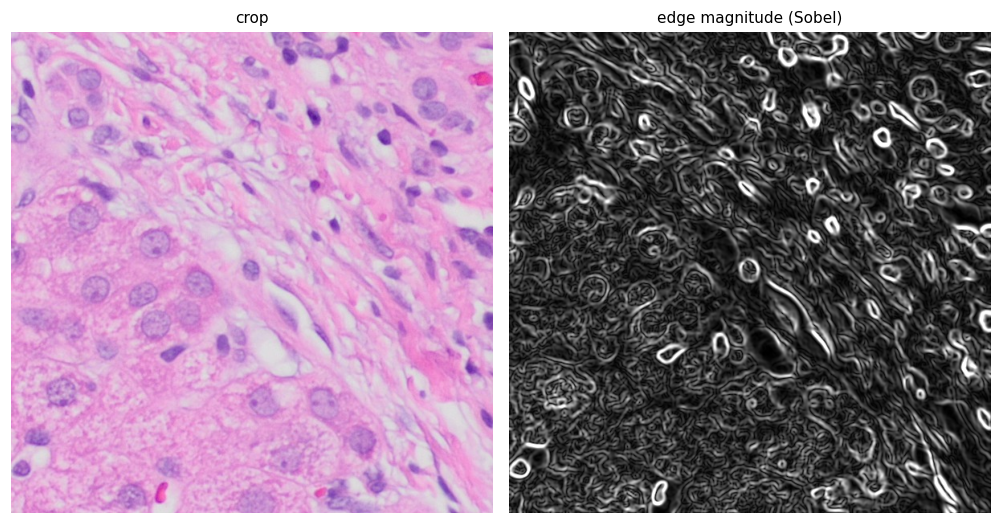

In [5]:
smooth = gaussian_blur(to_gray(HE), 1.5)
mag = np.hypot(convolve2d_fast(smooth, SOBEL_X), convolve2d_fast(smooth, SOBEL_Y))
show([HE, np.clip(mag / np.percentile(mag, 99), 0, 1)], ["crop", "edge magnitude (Sobel)"],
     ncols=2, size=4.6)

Edges are **everywhere**: rims of nuclei, cell walls, the fibres of the scar, the walls of the
white channels. An edge map answers "does something change here?", not "is this a nucleus?" -
to Sobel, the rim of a nucleus and the wall of a cell look alike.

What does tell them apart is the **stain**: nuclei are purple, almost everything else is pink.
The signal is colour.

> **Remember:** edges say *where* something changes, not *what* it is.

# Part 2 - colour is the signal

### RGB first

The obvious RGB rule for a purple nucleus: "bluer than green, and dark". Try three values of
"dark", all of them reasonable-looking.

**Predict:** going from "darker than 0.55" to "darker than 0.70", how much does the area called
"nucleus" change? 10%? Double?

bluer than green AND darker than 0.55:   3.1% of the field
bluer than green AND darker than 0.62:   8.5% of the field
bluer than green AND darker than 0.7:  28.2% of the field

'bluer than green' on its own is true for 99.8% of all pixels


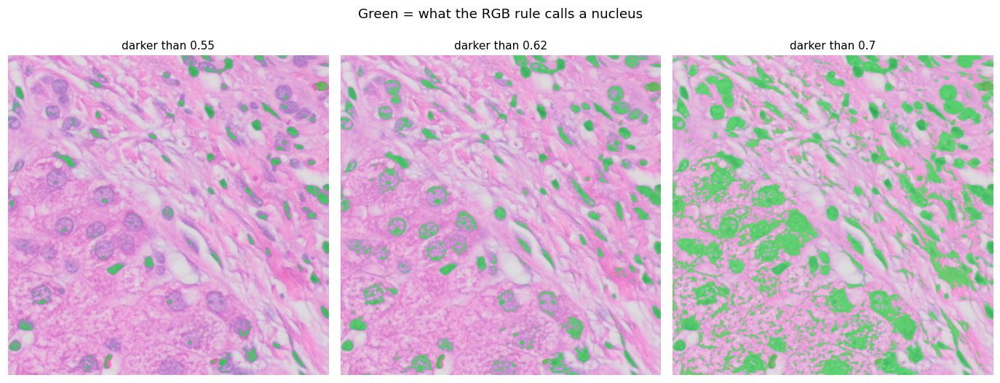

In [6]:
gray = to_gray(HE)
bluer = HE[..., 2] > HE[..., 1]
rgb_masks = {t: bluer & (gray < t) for t in (0.55, 0.62, 0.70)}
for t, m in rgb_masks.items():
    print(f"bluer than green AND darker than {t}: {100 * m.mean():5.1f}% of the field")
print(f"\n'bluer than green' on its own is true for {100 * bluer.mean():.1f}% of all pixels")
show([tint(HE, m) for m in rgb_masks.values()], [f"darker than {t}" for t in rgb_masks],
     ncols=3, size=4.2, suptitle="Green = what the RGB rule calls a nucleus")

From 3% of the field to 28%: one threshold moved by 0.15, and the answer grew **9x**. At 0.55
only the darkest scar nuclei are found and the pale liver-cell nuclei are missed; at 0.70 whole
stretches of pink cytoplasm turn green.

And "bluer than green" does nothing: it is true for 99.8% of the pixels, pink or purple. The rule
is a **brightness threshold in disguise** - and brightness cannot tell pink from purple.

### Hue

HSV ([33], HW1b) splits a colour into three numbers that mean different things:

- **hue** - *which* colour, as an angle around the colour wheel: 0 is red, 120 green, 240 blue,
  and 360 is red again;
- **saturation** - how far the colour is from grey;
- **value** - how bright it is.

H&E lives in one small slice of the wheel:

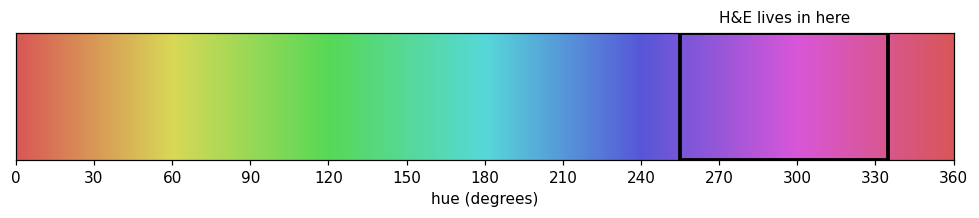

In [7]:
wheel = np.linspace(0, 1, 721)
strip = hsv_to_rgb(np.dstack([np.tile(wheel, (30, 1)), np.full((30, 721), 0.6), np.full((30, 721), 0.85)]))
fig, ax = plt.subplots(figsize=(11, 1.5))
ax.imshow(strip, extent=[0, 360, 0, 1], aspect="auto")
ax.axvspan(255, 335, fill=False, ec="k", lw=2.5)
ax.text(295, 1.06, "H&E lives in here", ha="center", va="bottom", transform=ax.get_xaxis_transform())
ax.set_xticks(range(0, 361, 30))
ax.set_yticks([])
ax.set_xlabel("hue (degrees)")
plt.show()

**Predict:** take a typical nucleus pixel and darken it - multiply R, G and B by 0.8, then 0.6,
then 0.4. Same stain, less light. What happens to its three RGB numbers? To its hue?

(The "typical" pixels below are medians over thousands of pixels from the crop: one from the
purple nuclei, one from the pink cytoplasm.)

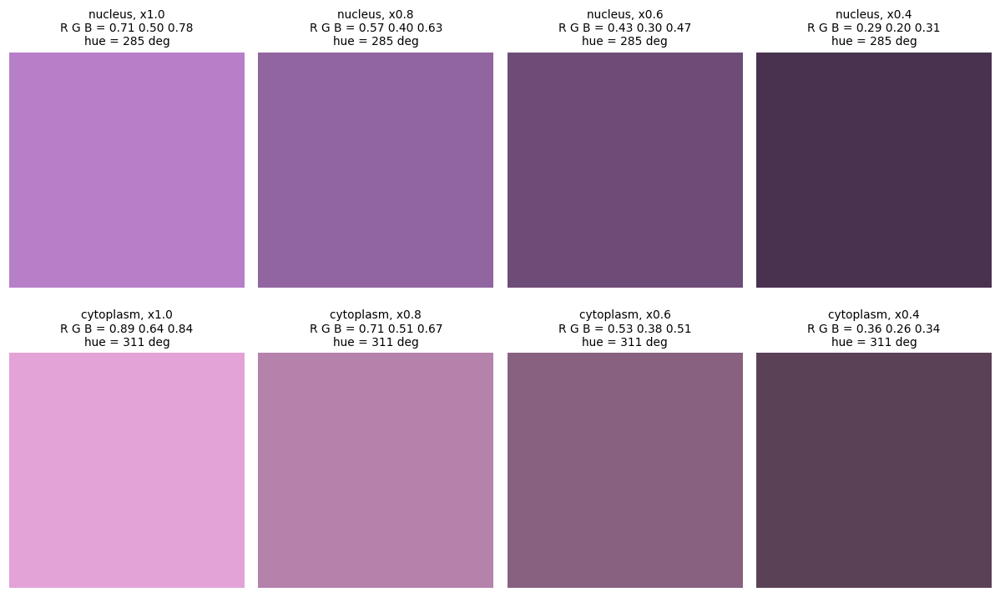

In [8]:
hsv_he = rgb_to_hsv(HE)
hue_deg, Ss, Vv = hsv_he[..., 0] * 360, hsv_he[..., 1], hsv_he[..., 2]
nucleus_px = np.median(HE[(hue_deg > 275) & (hue_deg < 290) & (Ss > 0.18)], axis=0)
cytoplasm_px = np.median(HE[(hue_deg > 305) & (hue_deg < 320) & (Ss > 0.18)], axis=0)

fig, axes = plt.subplots(2, 4, figsize=(11, 7.0))
for row, (name, px) in enumerate([("nucleus", nucleus_px), ("cytoplasm", cytoplasm_px)]):
    for col, k in enumerate([1.0, 0.8, 0.6, 0.4]):
        rgb = px * k
        h = rgb_to_hsv(rgb)[0]
        ax = axes[row, col]
        ax.imshow(np.ones((10, 10, 3)) * rgb)
        ax.set_title(f"{name}, x{k}\nR G B = {rgb[0]:.2f} {rgb[1]:.2f} {rgb[2]:.2f}\nhue = {360 * h:.0f} deg",
                     fontsize=9)
        ax.axis("off")
fig.tight_layout()
plt.show()

All three RGB numbers move. The hue does not move at all. Look across the rows, too: the
cytoplasm at x0.6 is *darker* than the nucleus at x1.0. A brightness rule would call that
cytoplasm a nucleus.

Why hue stays put: every branch of the hue formula is a ratio of channel *differences*. For a
pixel whose largest channel is blue (our nuclei), for example,

$$\text{hue} = 60^\circ \cdot \left(4 + \frac{R - G}{\max(R,G,B) - \min(R,G,B)}\right).$$

Multiply R, G and B by the same $k$, and the top and the bottom of the fraction both get the
factor $k$: it cancels. Hue is blind to *how much* light there is, by construction.

Hold on to one detail for Part 7: the cancellation needs the **same** $k$ on all three channels.

### Your turn 1: the hue formula by hand

For a pixel whose largest channel is **red** - like the typical cytoplasm pixel - the branch of
the formula is

$$\text{hue} = 60^\circ \cdot \frac{G - B}{\max(R,G,B) - \min(R,G,B)},$$

wrapped into 0-360 degrees (add 360 if it comes out negative; in Python, `% 360` does it).

1. Compute the hue of `cytoplasm_px` with it.
2. Compute it again for `cytoplasm_px * 0.5`. Before you run: will it change?

In [9]:
r, g, b = cytoplasm_px
my_hue = None        # replace None with the formula
my_hue_dark = None   # the same formula, for cytoplasm_px * 0.5
check("hue of the cytoplasm pixel", my_hue, 360 * rgb_to_hsv(cytoplasm_px)[0], tol=0.5)
check("hue of the darkened pixel ", my_hue_dark, 360 * rgb_to_hsv(cytoplasm_px * 0.5)[0], tol=0.5)

hue of the cytoplasm pixel: not answered yet - replace the None above
hue of the darkened pixel : not answered yet - replace the None above


**Solution** - read it after you have tried the cell above:

In [10]:
r, g, b = cytoplasm_px
my_hue = 60 * (g - b) / (max(r, g, b) - min(r, g, b)) % 360
r2, g2, b2 = cytoplasm_px * 0.5
my_hue_dark = 60 * (g2 - b2) / (max(r2, g2, b2) - min(r2, g2, b2)) % 360
check("hue of the cytoplasm pixel", my_hue, 360 * rgb_to_hsv(cytoplasm_px)[0], tol=0.5)
check("hue of the darkened pixel ", my_hue_dark, 360 * rgb_to_hsv(cytoplasm_px * 0.5)[0], tol=0.5)

hue of the cytoplasm pixel: 311.2 - correct
hue of the darkened pixel : 311.2 - correct


### One catch: grey has no hue

For a grey pixel, $\max - \min$ is almost zero, so the hue is a ratio of two tiny numbers -
camera noise decides it. The white channels in the crop are like that. Compare the hues of
pixels with some colour against those of nearly grey ones:

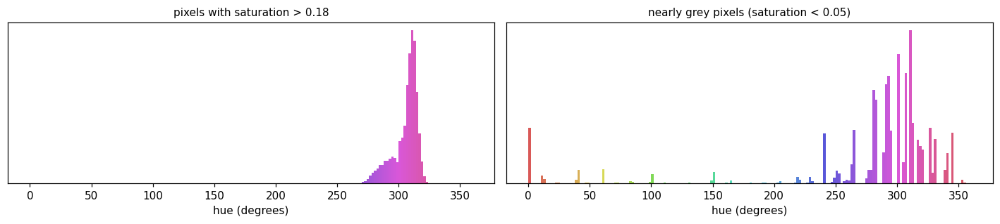

share with a 'nucleus' hue (270-295 deg): coloured pixels 16%, nearly grey pixels 31%


In [11]:
SAT_FLOOR = 0.18
coloured = Ss > SAT_FLOOR
grey = Ss < 0.05
fig, axes = plt.subplots(1, 2, figsize=(13, 3.0))
hue_hist(axes[0], hue_deg[coloured], 0, 360)
axes[0].set_title(f"pixels with saturation > {SAT_FLOOR}", fontsize=10)
hue_hist(axes[1], hue_deg[grey], 0, 360)
axes[1].set_title("nearly grey pixels (saturation < 0.05)", fontsize=10)
fig.tight_layout()
plt.show()
band = (hue_deg > 270) & (hue_deg < 295)
print(f"share with a 'nucleus' hue (270-295 deg): coloured pixels {100 * band[coloured].mean():.0f}%, "
      f"nearly grey pixels {100 * band[grey].mean():.0f}%")

Coloured pixels sit in one tight cluster. Nearly grey pixels are scattered around the whole
wheel, in spikes: when the three channels differ by only a step or two out of 255, only a
handful of angles are possible. And almost a third of them land in the nuclei's hue band by
accident - twice the rate of the coloured pixels. So every rule below starts with a
**saturation floor**: only pixels with saturation above 0.18 get a vote.

Now the hue of every coloured pixel, zoomed in on H&E's slice of the wheel, each bar painted in
its own colour:

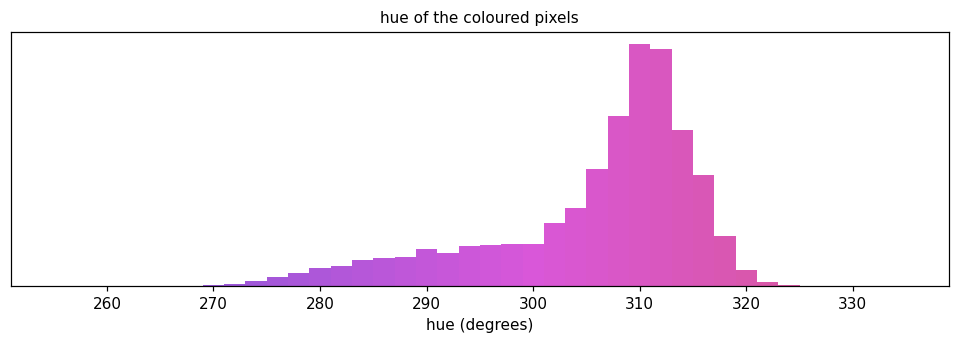

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.0))
hue_hist(ax, hue_deg[coloured], 255, 335)
ax.set_title("hue of the coloured pixels", fontsize=10)
plt.show()

A **purple shoulder** (haematoxylin: the nuclei) next to a **pink peak** (eosin: the cytoplasm).
Not two clean islands - but separable along one axis, which RGB never managed.

One more picture, the one the rest of the notebook keeps coming back to. Every coloured pixel is
placed by its **hue** (left to right) and its **brightness** (bottom to top); darker grey means
more pixels.

**Predict:** you may draw one straight line - vertical (a hue cut) or horizontal (a brightness
cut). Which one separates the two clouds better?

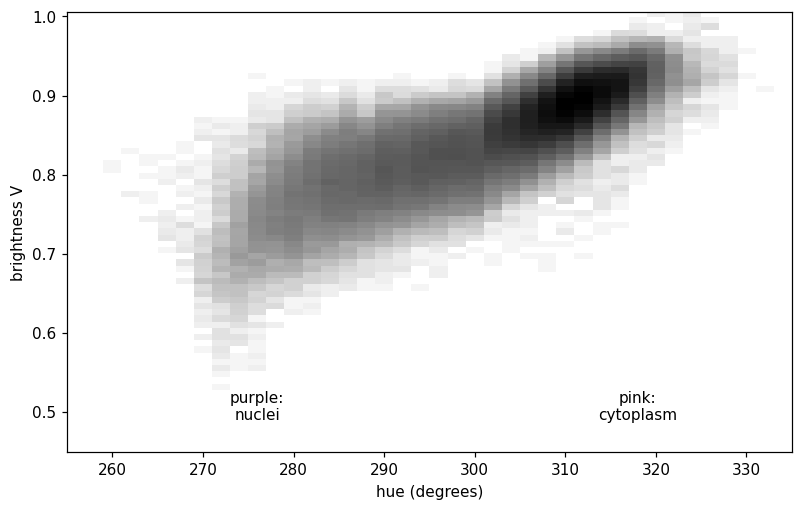

In [13]:
MAP, XE, YE = np.histogram2d(hue_deg[coloured], Vv[coloured], bins=[np.arange(255, 337, 2), V_BINS[57:]])


def draw_map(ax):
    ax.imshow(np.log1p(MAP.T), origin="lower", extent=[XE[0], XE[-1], YE[0], YE[-1]],
              aspect="auto", cmap="Greys")
    ax.set_xlabel("hue (degrees)")
    ax.set_ylabel("brightness V")


fig, ax = plt.subplots(figsize=(8.5, 5.2))
draw_map(ax)
ax.text(276, 0.49, "purple:\nnuclei", ha="center", fontsize=10)
ax.text(318, 0.49, "pink:\ncytoplasm", ha="center", fontsize=10)
plt.show()

The clouds lie along a **diagonal**: nuclei to the left and lower, cytoplasm to the right and
higher. A **vertical** line near 295 degrees runs through the thinner part between them. A
**horizontal** line cuts through both clouds - and that is, roughly, what the RGB rule was
doing: a brightness threshold. That is why it failed.

(A slanted line would beat both. Finding the best slanted line from labelled examples is exactly
what a linear classifier does. We have no labels - so: one vertical line.)

> **Remember:** hue is *which* colour, blind to brightness. It means nothing for grey pixels,
> so we only look at pixels with some saturation.

### Check yourself

1. Pixel A is (0.40, 0.30, 0.45) and pixel B is (0.80, 0.60, 0.90). Same hue? Same brightness?

<details>
<summary><b>Answer</b></summary>

B is exactly 2 x A, so the factor cancels: **same hue** (and the same saturation). The brightness V = max(R, G, B) doubles, from 0.45 to 0.90.

</details>

2. Hue already ignores brightness. Why does the rule still need a saturation floor?

<details>
<summary><b>Answer</b></summary>

For a nearly grey pixel max - min is almost zero, so its hue is decided by noise - and 31% of the nearly grey pixels land in the nuclei's band by accident. The floor keeps only pixels whose hue means something.

</details>

3. On the hue-brightness map, what kind of line is the RGB rule "darker than 0.62", roughly - and why does that doom it?

<details>
<summary><b>Answer</b></summary>

A horizontal line, a brightness cut. The two clouds overlap in brightness, so any horizontal line cuts through both of them.

</details>

# Part 3 - build the nuclei mask

Two conditions so far: hue between 270 and 295 degrees, saturation above 0.18. We build the mask
on a zoom that holds **both kinds of nuclei** in this liver:

- **liver cells** (hepatocytes, upper left): big round nuclei whose chromatin is loosely packed,
  so they look **pale**;
- **scar cells** (inflammatory cells and fibroblasts, lower left and right): small or
  spindle-shaped nuclei with tightly packed chromatin, so they look **dark**.

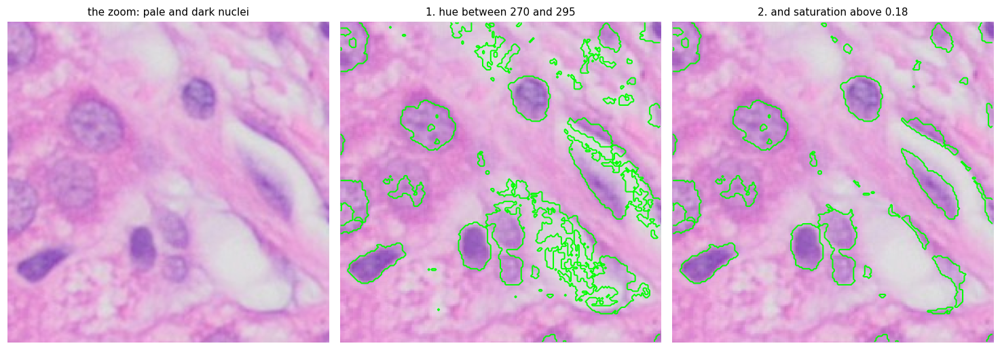

In [14]:
HUE_LO, HUE_HI = 270, 295
Z = (slice(250, 450), slice(180, 380))
in_band = (hue_deg > HUE_LO) & (hue_deg < HUE_HI)
m_hue = in_band & coloured
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.7))
axes[0].imshow(HE[Z])
axes[0].set_title("the zoom: pale and dark nuclei", fontsize=10)
axes[0].axis("off")
outline(axes[1], HE[Z], in_band[Z], title=f"1. hue between {HUE_LO} and {HUE_HI}")
outline(axes[2], HE[Z], m_hue[Z], title=f"2. and saturation above {SAT_FLOOR}")
fig.tight_layout()
plt.show()

Hue alone (middle) also grabs the pale white channel in the lower middle, and bits of the one at
the upper right: nearly grey pixels whose hue landed in the band by accident - exactly what the
grey-pixel histogram warned about. The saturation floor (right) removes them. What is left:
the pale nuclei and the dark ones, both outlined.

### A tempting third condition

"Nuclei are dark" - so why not also require brightness below, say, 0.78?

**Predict:** what happens to the pale nuclei?

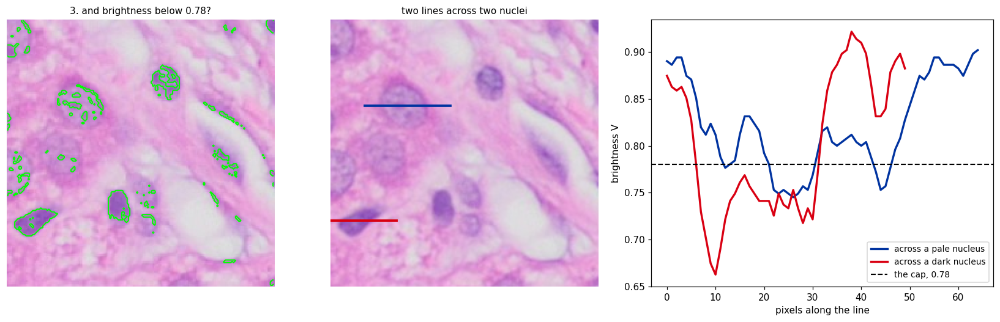

In [15]:
V_CAP = 0.78
PROFILES = [(64, 25, 90, BLUE, "across a pale nucleus"), (150, 0, 50, RED, "across a dark nucleus")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), gridspec_kw={"width_ratios": [1, 1, 1.25]})
outline(axes[0], HE[Z], (m_hue & (Vv < V_CAP))[Z], title=f"3. and brightness below {V_CAP}?")
axes[1].imshow(HE[Z])
axes[1].set_title("two lines across two nuclei", fontsize=10)
axes[1].axis("off")
for row, c0, c1, colour, name in PROFILES:
    axes[1].plot([c0, c1 - 1], [row, row], color=colour, lw=2.5)
    axes[2].plot(np.arange(c1 - c0), Vv[Z][row, c0:c1], color=colour, lw=2.2, label=name)
axes[2].axhline(V_CAP, color="k", ls="--", lw=1.4, label=f"the cap, {V_CAP}")
axes[2].set_xlabel("pixels along the line")
axes[2].set_ylabel("brightness V")
axes[2].legend(fontsize=9)
fig.tight_layout()
plt.show()

The cap keeps the dark nuclei whole and **shreds the pale ones** into specks. The profiles show
why. Across the dark nucleus (red) the brightness drops well below the cap and stays there.
Across the pale nucleus (blue) it wanders around the cap, above it about as often as below - so
part of the nucleus passes and part does not, and it comes out in pieces.

One brightness cap cannot serve two kinds of nuclei, so we leave it out. (Part 5 shows what
keeping it would have cost.)

### Opening: erosion, then dilation

The mask still has specks: single purple-ish pixels in the cytoplasm, thin purple fibres. [48]'s
fix slides a 3x3 window over the mask:

- **erosion**: a pixel stays on only if its **whole window** is on - the **min** of the window;
- **dilation**: a pixel turns on if **anything** in its window is on - the **max** of the window.

Erosion, then dilation, is an **opening**. First on a toy mask small enough to check by hand: a
5x5 block (a nucleus), a one-pixel speck, a 2x2 speck, and a fibre one pixel thick.

**Predict:** which shapes survive the erosion? What does the block look like after it - and
after the dilation? How many pixels are on at each step?

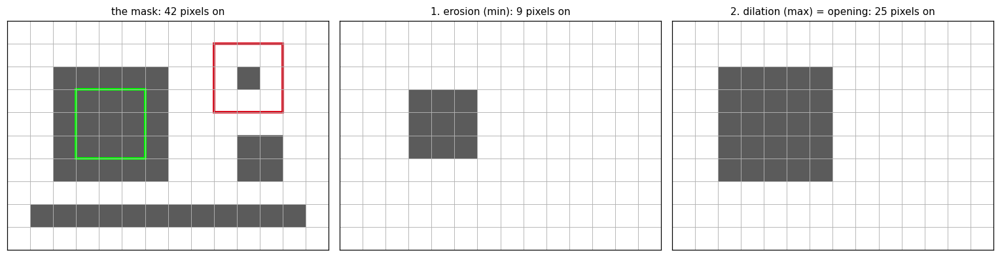

In [16]:
WINDOW = np.ones((3, 3), bool)
toy = np.zeros((10, 14), bool)
toy[2:7, 2:7] = True      # a nucleus
toy[2, 10] = True         # a one-pixel speck
toy[5:7, 10:12] = True    # a 2x2 speck
toy[8, 1:13] = True       # a fibre, one pixel thick
toy_eroded = ndimage.binary_erosion(toy, structure=WINDOW)
toy_opened = ndimage.binary_dilation(toy_eroded, structure=WINDOW)

# erosion IS a min filter and dilation IS a max filter - checked, not just claimed
as_int = lambda m: m.astype(np.uint8)
assert np.array_equal(as_int(toy_eroded), ndimage.minimum_filter(as_int(toy), size=3, mode="constant"))
assert np.array_equal(as_int(toy_opened), ndimage.maximum_filter(as_int(toy_eroded), size=3, mode="constant"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, m, t in zip(axes, [toy, toy_eroded, toy_opened],
                    ["the mask", "1. erosion (min)", "2. dilation (max) = opening"]):
    ax.imshow(m, cmap="Greys", vmin=0, vmax=1.4)
    ax.set_xticks(np.arange(-0.5, 14, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
    ax.grid(which="minor", color="0.7", lw=0.6)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    ax.set_title(f"{t}: {m.sum()} pixels on", fontsize=10)
for (r, c), colour in [((4, 4), "lime"), ((2, 10), RED)]:
    axes[0].add_patch(plt.Rectangle((c - 1.5, r - 1.5), 3, 3, fill=False, ec=colour, lw=2.5))
fig.tight_layout()
plt.show()

The green window sits inside the block: all nine pixels are on, the min is 1, the pixel
survives. The red window sits on the speck: eight of its nine pixels are off, the min is 0, the
speck is gone. Everything thinner than the window - both specks and the fibre - vanishes in the
erosion and never comes back. The block shrinks to 3x3, and the dilation grows it back to 5x5.

**Predict:** now give the block a one-pixel-wide tail sticking out to the right. Does the
opening give the tail back?

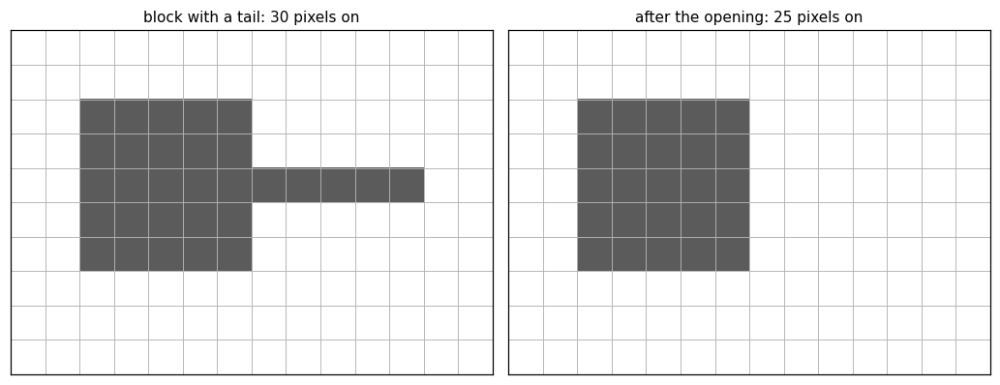

In [17]:
toy_tail = np.zeros((10, 14), bool)
toy_tail[2:7, 2:7] = True    # the same block
toy_tail[4, 7:12] = True     # and a tail, one pixel thick
tail_opened = ndimage.binary_opening(toy_tail, structure=WINDOW)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7))
for ax, m, t in zip(axes, [toy_tail, tail_opened], ["block with a tail", "after the opening"]):
    ax.imshow(m, cmap="Greys", vmin=0, vmax=1.4)
    ax.set_xticks(np.arange(-0.5, 14, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
    ax.grid(which="minor", color="0.7", lw=0.6)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    ax.set_title(f"{t}: {m.sum()} pixels on", fontsize=10)
fig.tight_layout()
plt.show()

No: the opening cuts **thin parts of objects** too, not only thin objects. Whatever no 3x3 square
fits inside is gone for good. On real tissue that trims the thin ends of spindle-shaped nuclei -
a small price for losing the specks.

Now the real mask:

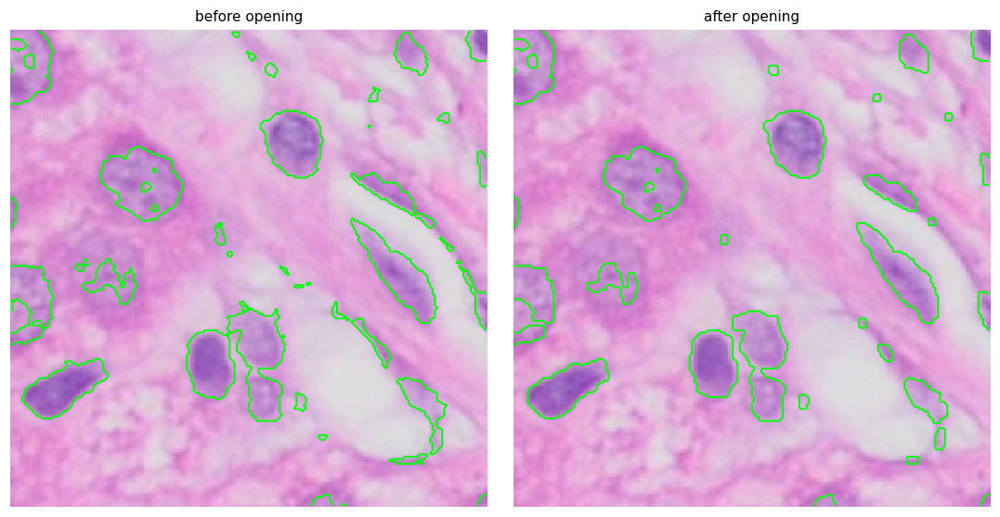

before opening :  343 separate blobs in the whole crop
after opening  :  146 separate blobs in the whole crop


In [18]:
nuclei = ndimage.binary_opening(m_hue, structure=WINDOW)
fig, axes = plt.subplots(1, 2, figsize=(10, 5.0))
outline(axes[0], HE[Z], m_hue[Z], title="before opening")
outline(axes[1], HE[Z], nuclei[Z], title="after opening")
fig.tight_layout()
plt.show()
for name, m in [("before opening", m_hue), ("after opening", nuclei)]:
    print(f"{name:15s}: {ndimage.label(m)[1]:4d} separate blobs in the whole crop")

The specks and thin fibres are gone (compare the two blob counts), and the nuclei kept their
shape.

> **Remember:** erosion is a min over the window, dilation a max. An opening deletes everything
> thinner than the window - whole specks, and thin parts of bigger objects - and gives the rest
> its shape back.

### Check yourself

1. With a 5x5 window instead of 3x3, what else would the opening delete?

<details>
<summary><b>Answer</b></summary>

Everything that no 5x5 square fits inside: the 3x3 block would now vanish, and on the slide, small nuclei and thin spindle-shaped ones would go with the specks.

</details>

2. Dilation first, then erosion, is a **closing**. What does it do to a mask?

<details>
<summary><b>Answer</b></summary>

The mirror image of an opening: it fills holes and gaps narrower than the window and joins blobs that almost touch. Useful for the holes in pale nuclei - and dangerous, because it also glues neighbouring nuclei together.

</details>

3. Why can no single brightness cap work for both kinds of nuclei?

<details>
<summary><b>Answer</b></summary>

The dark nuclei sit well below any reasonable cap, but the pale ones wander above and below it, so a cap low enough to drop cytoplasm also cuts the pale nuclei into pieces.

</details>

# Part 4 - count the nuclei, then check the count

`ndimage.label` gives every group of touching "on" pixels its own number: a **connected
component**. Below, each component gets its own random colour. Blobs under 30 pixels are dropped
as debris.

146 blobs, 113 of them at least 30 px: that is the nucleus count of the crop


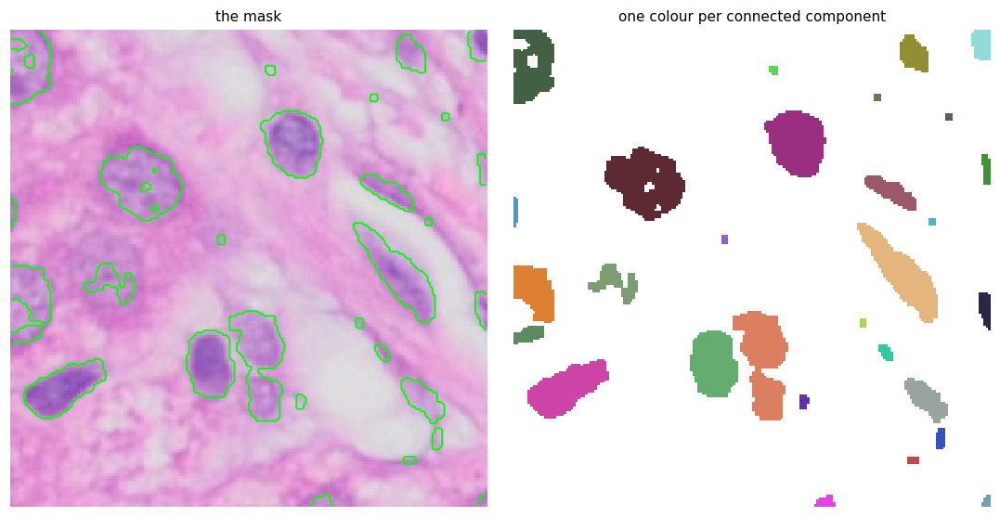

In [19]:
MIN_PX = 30


def count_blobs(mask):
    labels, n = ndimage.label(mask)
    sizes = ndimage.sum(mask, labels, range(1, n + 1))
    return labels, sizes, sizes >= MIN_PX


labels, sizes, keep = count_blobs(nuclei)
print(f"{len(sizes)} blobs, {keep.sum()} of them at least {MIN_PX} px: that is the nucleus count of the crop")

rng = np.random.default_rng(SEED)
palette = ListedColormap(np.vstack([[1, 1, 1], rng.uniform(0.15, 0.9, size=(len(sizes), 3))]))
fig, axes = plt.subplots(1, 2, figsize=(10, 5.0))
outline(axes[0], HE[Z], nuclei[Z], title="the mask")
axes[1].imshow(labels[Z], cmap=palette, vmin=0, vmax=len(sizes), interpolation="nearest")
axes[1].set_title("one colour per connected component", fontsize=10)
axes[1].axis("off")
fig.tight_layout()
plt.show()

### Your count: you are the ground truth

Nobody has labelled a single nucleus in these slides, so there is no score to check the count
against - except your own eyes. **Count the nuclei in the patch below twice, with two rules,
and write both numbers down before running the cell after it:**

- **rule A:** count a nucleus only if it lies **entirely inside** the patch;
- **rule B:** count every nucleus that **touches** the patch, even a sliver of one.

Count the pale ones too. Also note how many you were **unsure** about.

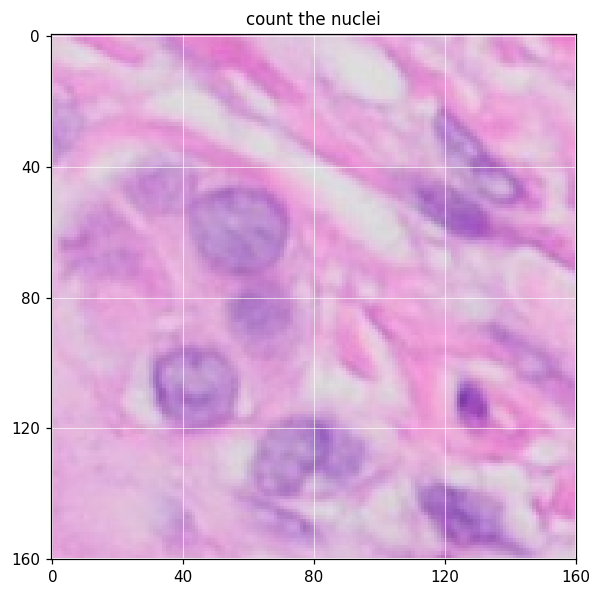

In [20]:
PATCH = (slice(0, 160), slice(40, 200))
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.imshow(HE[PATCH], interpolation="nearest")
ax.set_xticks(range(0, 161, 40))
ax.set_yticks(range(0, 161, 40))
ax.grid(color="white", lw=0.6, alpha=0.7)
ax.set_title("count the nuclei", fontsize=11)
plt.show()

The pipeline uses a third rule: a blob counts if its **centre** falls inside the patch. Here is
every nucleus-sized blob it counted:

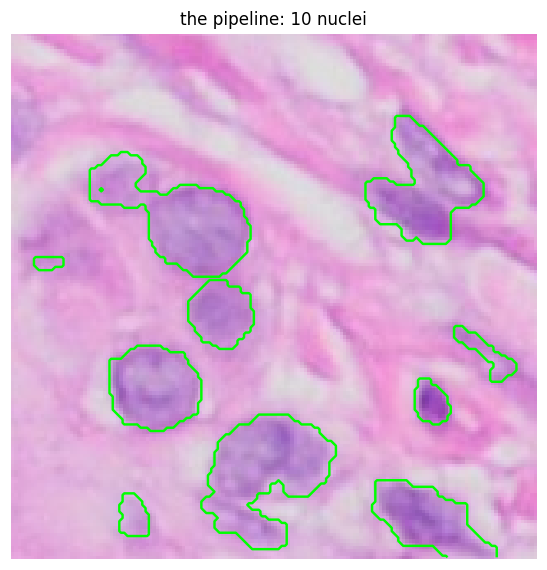

In [21]:
centres = ndimage.center_of_mass(nuclei, labels, range(1, len(sizes) + 1))
inside = [k for k, (cy, cx) in enumerate(centres)
          if keep[k] and PATCH[0].start <= cy < PATCH[0].stop and PATCH[1].start <= cx < PATCH[1].stop]
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.imshow(HE[PATCH], interpolation="nearest")
for k in inside:
    ax.contour(labels[PATCH] == k + 1, levels=[0.5], colors="lime", linewidths=1.6)
ax.set_title(f"the pipeline: {len(inside)} nuclei", fontsize=11)
ax.axis("off")
plt.show()

Compare with your two numbers. Then look at the outlines, not the number:

- the clear nuclei, pale and dark, are outlined whole - the hue rule handles both kinds;
- the elongated nuclei at the top right run together into **one** outline: more than one
  nucleus, one count;
- the big pale nucleus at the top left carries an extra lobe of faint purple - a second nucleus,
  or cytoplasm?
- two small blobs at the left and bottom edges are faint purple patches, each counted as a
  nucleus;
- nuclei cut by the patch edge: your rule A dropped them, rule B kept them, the pipeline keeps
  them when their centre is inside.

A merge (one too few) and a fragment (one too many) cancel, so the total can land near your
number **for the wrong reasons**. And look at your own two numbers: the same eyes on the same
patch gave two answers, depending only on the rule. Ground truth needs its rule written down
**before** anyone counts - and even then, two careful people disagree on the faint ones (your
"unsure" count). Separating touching nuclei properly is a job for instance segmentation - [51].

> **Remember:** a connected component is a group of touching pixels; a count is only as good as
> the objects behind it, so look at them. And without labels there is no score - only a person
> counting, with a rule.

### Check yourself

1. The pipeline counts 113 nuclei in the crop. Why can't we say how accurate that is?

<details>
<summary><b>Answer</b></summary>

Accuracy needs labels - a known right answer for each nucleus - and we have none. Our only check was your count of one small patch, and even that depended on the counting rule.

</details>

2. Two nuclei touch and become one blob. Does the opening split them?

<details>
<summary><b>Answer</b></summary>

Only if the bridge between them is thinner than the window - usually it is not. Splitting touching objects is what instance segmentation ([51]) is for.

</details>

Everything so far, in one function. It takes an image already converted to HSV (the conversion
is the slow part, so we do it once per image). Part 5 turns its knobs; Part 7 feeds it other
images.

In [22]:
def find_nuclei(hsv, hue_hi=HUE_HI, v_cap=None):
    h, s, v = hsv[..., 0] * 360, hsv[..., 1], hsv[..., 2]
    mask = (h > HUE_LO) & (h < hue_hi) & (s > SAT_FLOOR)
    if v_cap is not None:
        mask &= v < v_cap
    return ndimage.binary_opening(mask, structure=WINDOW)


def n_nuclei(mask):
    return int(count_blobs(mask)[2].sum())


assert n_nuclei(find_nuclei(hsv_he)) == keep.sum()
print(f"find_nuclei(hsv_he): {n_nuclei(find_nuclei(hsv_he))} nuclei")

find_nuclei(hsv_he): 113 nuclei


# Part 5 - where did the thresholds come from?

295 degrees came from looking at a histogram, then trying values and keeping one that looked
right: [08]'s grid search, done by eye. In [08] every candidate got a **score** on a validation
set. Here there is none. The one question we can still ask is whether the answer is **stable**:
if a small nudge of a knob moves the count a lot, the count is an artefact of where we stopped.

Two knobs to drive: the hue edge, and Part 3's brightness cap (at 1.00 it is off). The blue box
on the map is what the rule keeps.

**Predict before you touch anything:** look at the map in Part 2. Which knob will make the count
jump, and which will barely move it?

In [23]:
# each slider move reruns find_nuclei on the whole crop: well under a second
def explore(hue_edge=HUE_HI, brightness_cap=1.0):
    cap = None if brightness_cap >= 1 else brightness_cap
    mask = find_nuclei(hsv_he, hue_edge, cap)
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 5.2))
    outline(a0, HE[Z], mask[Z], title=f"{n_nuclei(mask)} nuclei in the whole crop")
    draw_map(a1)
    top = brightness_cap if cap is not None else YE[-1]
    a1.add_patch(plt.Rectangle((HUE_LO, YE[0]), hue_edge - HUE_LO, top - YE[0],
                               fc=BLUE, alpha=0.15, ec=BLUE, lw=2))
    a1.set_title("the blue box is what the rule keeps", fontsize=10)
    fig.tight_layout()
    plt.show()


interact(explore,
         hue_edge=IntSlider(value=HUE_HI, min=278, max=318, step=1, continuous_update=False),
         brightness_cap=FloatSlider(value=1.0, min=0.66, max=1.0, step=0.01, continuous_update=False));

interactive(children=(IntSlider(value=295, continuous_update=False, description='hue_edge', max=318, min=278),…

Three things to try, each with what you should see:

1. Cap at 1.00: slide the hue edge from 285 to 300.

<details>
<summary><b>What you should see</b></summary>

The count climbs gently, from about 75 at 285 to about 125 at 300 - no jumps.

</details>

2. Hue edge at 295: slide the cap from 1.00 down to 0.70. Watch the count **and** the pale nuclei in the zoom.

<details>
<summary><b>What you should see</b></summary>

Nothing happens until about 0.86: the cap is above almost every purple pixel. Then the count *rises* to about 134 near 0.82 - pale nuclei cut into pieces, each piece counted - and then falls off a cliff: 82 at 0.78, 24 at 0.74, a handful at 0.70. In the zoom the pale nuclei fall apart first.

</details>

3. Push the hue edge past 305. What happens in the zoom - and why does the count eventually *drop*?

<details>
<summary><b>What you should see</b></summary>

The box reaches into the pink cloud: cytoplasm floods into the mask, its fragments get counted, and the count shoots up to about 270 near 309. Past that the flood joins everything into a few giant blobs, and the count collapses.

</details>

The same experiment for every setting at once, with each knob's histogram underneath:

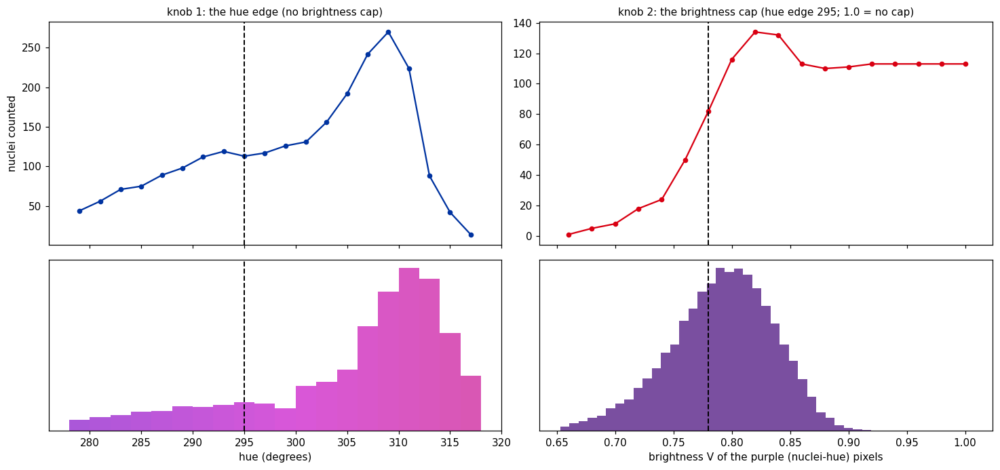

In [24]:
# ~6 s: find_nuclei runs 38 times
hue_edges = np.arange(279, 319, 2)
caps = np.round(np.arange(0.66, 1.001, 0.02), 2)
hue_counts = [n_nuclei(find_nuclei(hsv_he, e)) for e in hue_edges]
cap_counts = [n_nuclei(find_nuclei(hsv_he, HUE_HI, c if c < 1 else None)) for c in caps]
purple_v = Vv[m_hue]

fig, axes = plt.subplots(2, 2, figsize=(13.5, 6.4), sharex="col", gridspec_kw={"height_ratios": [1.3, 1]})
axes[0, 0].plot(hue_edges, hue_counts, "o-", color=BLUE, ms=4)
axes[0, 0].set_ylabel("nuclei counted")
axes[0, 0].set_title("knob 1: the hue edge (no brightness cap)", fontsize=10)
hue_hist(axes[1, 0], hue_deg[coloured], 278, 318)
axes[0, 1].plot(caps, cap_counts, "o-", color=RED, ms=4)
axes[0, 1].set_title(f"knob 2: the brightness cap (hue edge {HUE_HI}; 1.0 = no cap)", fontsize=10)
axes[1, 1].hist(purple_v, bins=V_BINS[83:], color="#7a4fa0")
axes[1, 1].set_xlabel("brightness V of the purple (nuclei-hue) pixels")
axes[1, 1].set_yticks([])
for col, cut in [(0, HUE_HI), (1, V_CAP)]:
    for row in (0, 1):
        axes[row, col].axvline(cut, color="k", ls="--", lw=1.3)
fig.tight_layout()
plt.show()

Why does one knob sit on a gentle slope and the other on a cliff? Moving a threshold from $t$ to
$t + \Delta t$ flips exactly the pixels lying between the two positions. If $p(t)$ is the height
of the histogram at the cut, that is about

$$\Delta(\text{pixels}) \approx p(t)\,\Delta t .$$

A cut where the histogram is **low** flips few pixels when nudged; a cut where it is **high**
flips many. Measure it at our two cuts:

In [25]:
near_hue = np.mean(np.abs(hue_deg[coloured] - HUE_HI) < 5)
near_cap = np.mean(np.abs(purple_v - V_CAP) < 0.04)
print(f"coloured pixels within 5 degrees of the hue edge {HUE_HI}:    {100 * near_hue:3.0f}%")
print(f"purple pixels within 0.04 of the brightness cap {V_CAP}:   {100 * near_cap:3.0f}%\n")
for name, settings in [("hue edge", [(HUE_HI - 5, None), (HUE_HI, None), (HUE_HI + 5, None)]),
                       ("brightness cap", [(HUE_HI, V_CAP - 0.04), (HUE_HI, V_CAP), (HUE_HI, V_CAP + 0.04)])]:
    counts = [n_nuclei(find_nuclei(hsv_he, e, c)) for e, c in settings]
    knob = [e for e, _ in settings] if name == "hue edge" else [round(c, 2) for _, c in settings]
    print(f"{name:15s} {knob[0]} / {knob[1]} / {knob[2]}:  {counts[0]} / {counts[1]} / {counts[2]} nuclei")

coloured pixels within 5 degrees of the hue edge 295:     11%
purple pixels within 0.04 of the brightness cap 0.78:    61%

hue edge        290 / 295 / 300:  112 / 113 / 127 nuclei


brightness cap  0.74 / 0.78 / 0.82:  24 / 82 / 134 nuclei


The same nudge on both knobs, very different results:

- **The hue edge** sits in the low shoulder of its histogram: only 11% of the coloured pixels
  are within 5 degrees of it. Moving it 5 degrees either way changes the count from 113 to 112
  or 127. Not perfectly flat - the shoulder is low, not empty - but a gentle slope.
- **The brightness cap** sits on the peak of its histogram: 61% of the purple pixels are within
  0.04 of it. Moving it by 0.04 takes the count from 82 to 24 or 134 - a cliff. Between 0.80
  and 0.84 the count even *overshoots* the uncapped 113: pale nuclei cut into two or three
  pieces, each piece counted. Above about 0.86 the curve goes flat - but that plateau is the cap
  sitting above almost every purple pixel, the cap doing nothing. When a knob's only stable
  setting is "off", delete the knob - which is what Part 3 did.
- **Past about 300 degrees** the hue edge walks into the pink peak: cytoplasm leaks into the
  mask, its fragments get counted, and the count shoots up - then collapses as the leaking pink
  joins everything into a few giant blobs.

The strongest check of all - the real size of a nucleus in microns - is missing: it needs a
scale bar or the magnification, and neither image comes with one.

> **Remember:** put a threshold where its histogram is low. A cut through a peak is a cliff:
> the answer then says where you stopped, not what is in the image.

### Check yourself

1. A threshold sits where 40% of the pixels lie within 0.02 of it. Plateau or cliff?

<details>
<summary><b>Answer</b></summary>

A cliff: the histogram is high there, so any nudge flips a large share of the pixels.

</details>

2. Is there a setting for the brightness cap that is both stable and useful?

<details>
<summary><b>Answer</b></summary>

No. The purple pixels' brightness histogram is one hump with no valley in it, so the only flat stretch is above the hump - where the cap removes nothing. The honest fix is to delete the knob.

</details>

3. Why is the count a worse thing to watch than the mask's area, when you judge a threshold?

<details>
<summary><b>Answer</b></summary>

The count is not even monotonic: merges lower it and fragments raise it, so it can stay flat or drop while the mask changes completely (the hue edge past 309). The area moves smoothly with the threshold and says directly how many pixels flipped.

</details>

# Part 6 - slide B: how much of the liver is fat?

Slide B is a **Masson trichrome**: liver cells red, collagen (scar) **green**, and fat droplets
**white holes** - the fat dissolved away while the slide was being made. (The clinical cut-off
counts liver *cells* holding fat; we measure fat *area*, a stand-in.)

Two ideas from before carry the whole measurement: colour (Part 2) and connected components
(Part 4). First, this slide's hues and saturations:

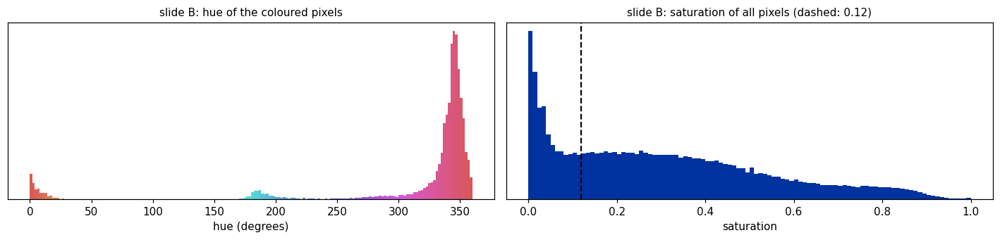

In [26]:
hsv_tri = rgb_to_hsv(TRI)
tri_hue, tri_sat, tri_val = hsv_tri[..., 0] * 360, hsv_tri[..., 1], hsv_tri[..., 2]
tri_coloured = tri_sat > 0.15
FAT_S, FAT_V = 0.12, 0.80
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
hue_hist(axes[0], tri_hue[tri_coloured], 0, 360)
axes[0].set_title("slide B: hue of the coloured pixels", fontsize=10)
axes[1].hist(tri_sat.ravel(), bins=np.linspace(0, 1, 101), color=BLUE)
axes[1].axvline(FAT_S, color="k", ls="--", lw=1.4)
axes[1].set_xlabel("saturation")
axes[1].set_yticks([])
axes[1].set_title(f"slide B: saturation of all pixels (dashed: {FAT_S})", fontsize=10)
fig.tight_layout()
plt.show()

Two stains, two peaks: the green-blue collagen near 185 degrees, and the red - **at both ends of
the axis**. Hue is an angle: 355 and 5 degrees are neighbours on the wheel, but they sit at
opposite ends of a straight axis. So one stain shows up as two peaks.

### Your turn 2: a rule for "red"

Write a mask `red` for the coloured pixels of slide B that are red. Use `tri_hue` (in degrees)
and `tri_coloured` (saturation above 0.15). The cell then prints what share of the coloured
pixels your mask holds - from the histogram, most of them.

<details>
<summary><b>Hint</b></summary>

Red sits above about 300 degrees **and** below about 30. For boolean masks, `|` means "or" and `&` means "and"; put brackets around each comparison.

</details>

In [27]:
red = None   # a boolean mask, the same shape as tri_hue
if red is None:
    print("not answered yet - replace the None above")
else:
    print(f"your red mask holds {100 * red[tri_coloured].mean():.0f}% of the coloured pixels")

not answered yet - replace the None above


**Solution** - read it after you have tried the cell above:

In [28]:
red = ((tri_hue > 300) | (tri_hue < 30)) & tri_coloured
print(f"your red mask holds {100 * red[tri_coloured].mean():.0f}% of the coloured pixels")
print(f"a single band (hue > 300 only) would hold {100 * (tri_hue[tri_coloured] > 300).mean():.0f}% - "
      f"it forgets the red past 0")

your red mask holds 91% of the coloured pixels
a single band (hue > 300 only) would hold 85% - it forgets the red past 0


About 91% with the wrap-around, 85% without it: a single band silently drops the red that wrapped
past 0 degrees.

Fat has no stain, so it is not in the hue picture at all. A fat droplet is a **white** pixel:
low saturation (the spike at the left of the saturation histogram), high brightness.

white pixels: 25.7% of the field


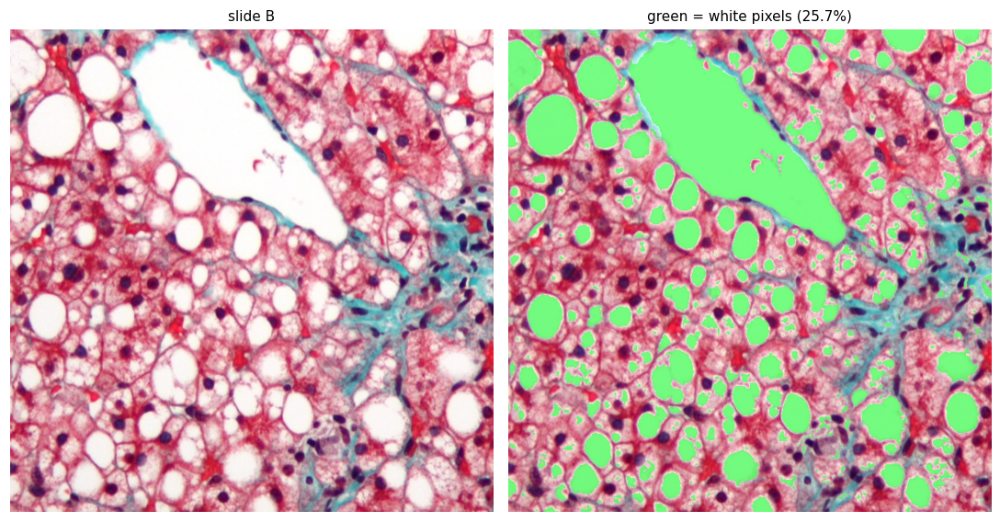

In [29]:
fat = (tri_sat < FAT_S) & (tri_val > FAT_V)
print(f"white pixels: {100 * fat.mean():.1f}% of the field")
show([TRI, tint(TRI, fat)], ["slide B", f"green = white pixels ({100 * fat.mean():.1f}%)"], ncols=2, size=5.0)

**Predict:** one of the green regions is not fat at all. Which one - and how much of the
percentage is it?

495 white blobs; the largest is 28255 px, 8x the next largest
white area:                    25.7% of the field
without that one blob:         17.8% of the field


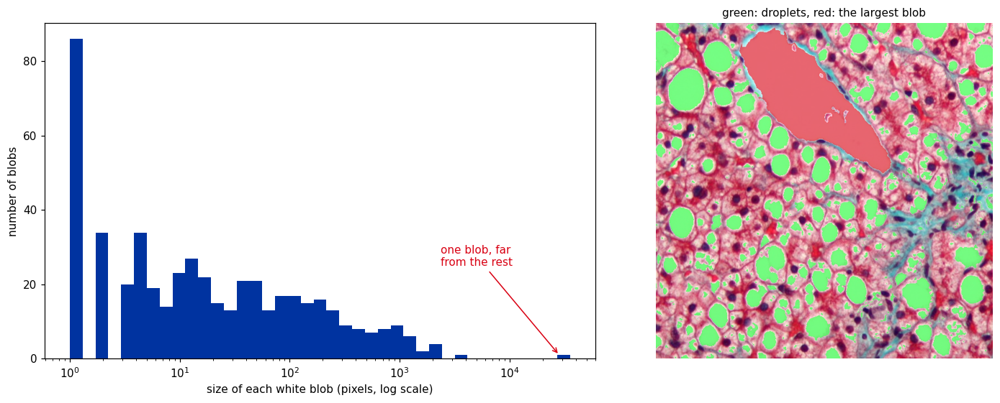

In [30]:
# ~4 s
fat_labels, fat_sizes, _ = count_blobs(fat)
biggest = int(np.argmax(fat_sizes))
vessel = fat_labels == biggest + 1
print(f"{len(fat_sizes)} white blobs; the largest is {fat_sizes[biggest]:.0f} px, "
      f"{fat_sizes[biggest] / np.sort(fat_sizes)[-2]:.0f}x the next largest")
print(f"white area:                   {100 * fat.mean():5.1f}% of the field")
print(f"without that one blob:        {100 * (fat & ~vessel).mean():5.1f}% of the field")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].hist(fat_sizes, bins=np.logspace(0, np.log10(fat_sizes.max()) + 0.1, 40), color=BLUE)
axes[0].set_xscale("log")
axes[0].annotate("one blob, far\nfrom the rest", xy=(fat_sizes[biggest], 1), xytext=(fat_sizes[biggest] / 12, 25),
                 arrowprops=dict(arrowstyle="->", color=RED), color=RED, fontsize=10)
axes[0].set_xlabel("size of each white blob (pixels, log scale)")
axes[0].set_ylabel("number of blobs")
axes[1].imshow(tint(tint(TRI, fat & ~vessel), vessel, colour=(0.85, 0.0, 0.07)))
axes[1].set_title("green: droplets, red: the largest blob", fontsize=10)
axes[1].axis("off")
fig.tight_layout()
plt.show()

It is the **blood vessel** at the top: a hole like the droplets, and to a colour rule a hole is a
hole. One blob, 8x bigger than the next largest, and it alone was 8 points of the 25.7%: without
it, 17.8%.

Here a size check catches it - but "the largest blob is the vessel" is one more hand-picked rule
that works on this crop and nowhere else. A pathologist rejects the vessel by its shape and its
collagen wall without a second thought.

> **Remember:** colour finds *pixels*. It takes objects - connected components - to notice that
> one of them is the wrong kind of thing.

### Check yourself

1. Name a slide on which "the largest white blob is the vessel" gives the wrong fat number.

<details>
<summary><b>Answer</b></summary>

A slide with two vessels (the second one still counts as fat), or with none (the rule throws away the largest fat droplet instead).

</details>

2. Why did the fat rule use saturation and brightness, but no hue at all?

<details>
<summary><b>Answer</b></summary>

Fat is unstained: a white pixel has almost no saturation, so its hue is noise (Part 2's grey pixels). Low saturation plus high brightness is what "white" means.

</details>

# Part 7 - the honesty test: the same slide, a different scanner

The fair question is not "does the nuclei rule work on a different stain?" - a different stain
is a different question. It is: **the same slide, the same question, scanned on a different
day**. Two things change between scanners, lamps and cameras:

- **exposure** - more or less light: all three channels times **the same** number;
- **white balance** - each channel times **its own** number: a slightly warmer or cooler image.

Five versions of the zoom (simulated from the original): two exposures and two white balances,
each off by only a few percent. Can you tell them apart?

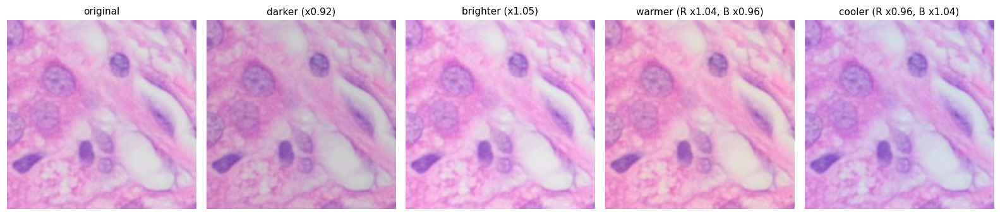

In [31]:
variants = {
    "original": HE,
    "darker (x0.92)": HE * 0.92,
    "brighter (x1.05)": np.clip(HE * 1.05, 0, 1),
    "warmer (R x1.04, B x0.96)": np.clip(HE * np.array([1.04, 1, 0.96]), 0, 1),
    "cooler (R x0.96, B x1.04)": np.clip(HE * np.array([0.96, 1, 1.04]), 0, 1),
}
show([img[Z] for img in variants.values()], list(variants), ncols=5, size=2.9)

**Predict, using Part 2:** which of the two changes does our hue rule survive? And the rule with
Part 3's tempting brightness cap?

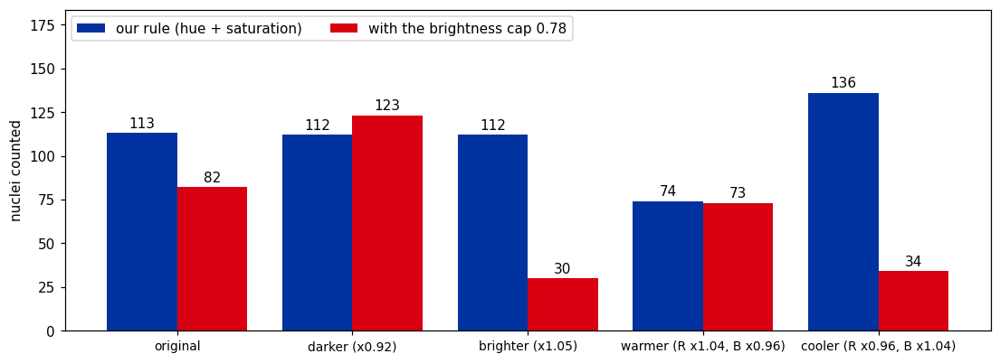

In [32]:
# ~4 s: one HSV conversion and two counts per version
variant_hsv = {name: rgb_to_hsv(img) for name, img in variants.items()}
rows = [(name, n_nuclei(find_nuclei(hsv)), n_nuclei(find_nuclei(hsv, v_cap=V_CAP)))
        for name, hsv in variant_hsv.items()]
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(12, 4.2))
ours = ax.bar(x - 0.2, [r[1] for r in rows], 0.4, color=BLUE, label="our rule (hue + saturation)")
capped = ax.bar(x + 0.2, [r[2] for r in rows], 0.4, color=RED, label=f"with the brightness cap {V_CAP}")
ax.bar_label(ours, padding=2)
ax.bar_label(capped, padding=2)
ax.set_xticks(x, [r[0] for r in rows], fontsize=9)
ax.set_ylabel("nuclei counted")
ax.set_ylim(0, 1.35 * max(max(r[1], r[2]) for r in rows))
ax.legend(loc="upper left", ncol=2)
plt.show()

- **Exposure** (darker, brighter): our rule barely moves - 113, 112, 112. That is Part 2's
  cancellation at work. The rule with the brightness cap swings from 82 to 123 and 30:
  brightness is exactly what it thresholds.
- **White balance** (warmer, cooler): our rule gives 74 and 136; the capped rule breaks too.

136 for the cooler image looks almost reasonable - a few more nuclei found? Look at what the
rule actually found:

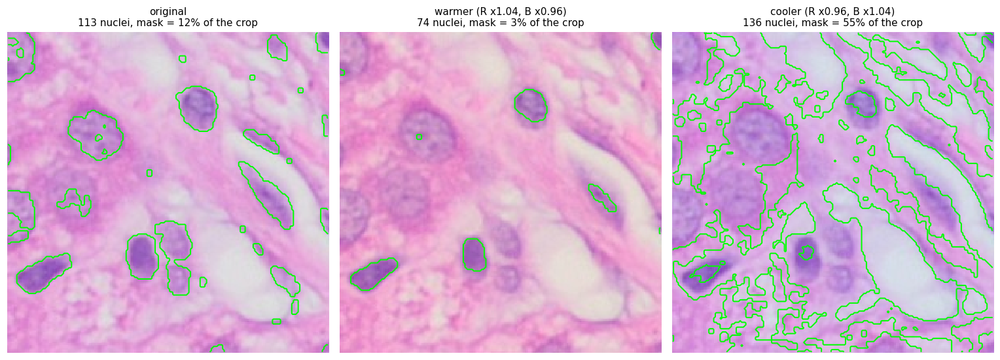

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, name in zip(axes, ["original", "warmer (R x1.04, B x0.96)", "cooler (R x0.96, B x1.04)"]):
    mask = find_nuclei(variant_hsv[name])
    outline(ax, variants[name][Z], mask[Z],
            title=f"{name}\n{n_nuclei(mask)} nuclei, mask = {100 * mask.mean():.0f}% of the crop")
fig.tight_layout()
plt.show()

**Warmer:** the pale nuclei drop out of the mask; only the darkest survive. **Cooler:** the mask
floods the cytoplasm - more than half of the crop is now "nucleus", and 136 is just the number
of islands in that flood. A plausible count on top of a nonsense mask: Part 4's lesson again -
look at the objects, not only the number.

Why white balance does it: the hues of all three versions, against our fixed band.

original                     median hue of the coloured pixels: 309 deg
warmer (R x1.04, B x0.96)    median hue of the coloured pixels: 323 deg
cooler (R x0.96, B x1.04)    median hue of the coloured pixels: 291 deg


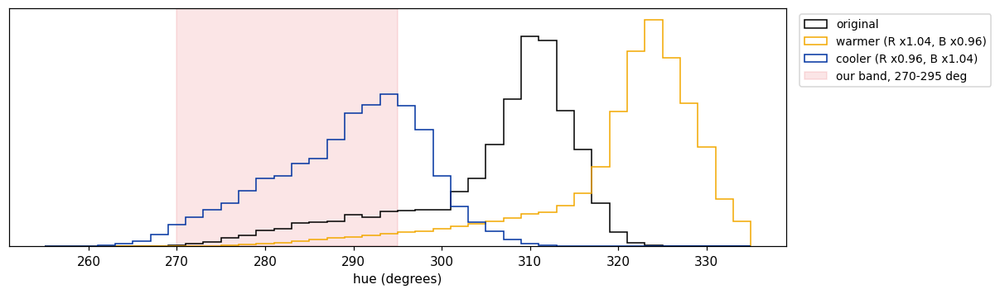

In [34]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for name, colour in [("original", "k"), ("warmer (R x1.04, B x0.96)", ORANGE), ("cooler (R x0.96, B x1.04)", BLUE)]:
    h, s = variant_hsv[name][..., 0] * 360, variant_hsv[name][..., 1]
    ax.hist(h[s > SAT_FLOOR], bins=np.arange(255, 337, 2), histtype="step", lw=2, color=colour, label=name)
    print(f"{name:28s} median hue of the coloured pixels: {np.median(h[s > SAT_FLOOR]):.0f} deg")
ax.axvspan(HUE_LO, HUE_HI, color=RED, alpha=0.1, label=f"our band, {HUE_LO}-{HUE_HI} deg")
ax.set_xlabel("hue (degrees)")
ax.set_yticks([])
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

The whole distribution slides - about 14 degrees up for the warmer image (median 309 to 323),
18 down for the cooler one (309 to 291) - while our band stays where we typed it. Warmer pushes
the purple shoulder (the nuclei) out of the band; cooler drags the pink peak (the cytoplasm)
into it. A different gain per channel changes the channel *differences* in the hue formula by
different amounts, so nothing cancels.

Why so far, from only 4%? H&E is a pale stain: in a typical pixel the three channels differ by
only about a quarter of their range (Part 2's typical nucleus pixel: R G B = 0.71 0.50 0.78), so
max - min is small, and a 4% nudge to R and B is large next to it. The same reason grey pixels
have noisy hue, in a milder form.

### Your turn 3: how small a shift breaks it?

4% broke the rule. How much less would? `count_after_shift(k)` makes the image warmer by a
fraction `k` (R times 1 + k, B times 1 - k; a negative `k` makes it cooler) and runs our rule.
Find the smallest warmer and the smallest cooler shift that moves the count more than 10% away
from 113. Print the mask's area too: it tells you more than the count does. Each try takes
about a second.

In [35]:
def count_after_shift(k):
    shifted = np.clip(HE * np.array([1 + k, 1, 1 - k]), 0, 1)
    mask = find_nuclei(rgb_to_hsv(shifted))
    return n_nuclei(mask), 100 * mask.mean()


count, area = count_after_shift(0.01)
print(f"k = 0.01: {count} nuclei, mask = {area:.1f}% of the crop")
# try more values of k, warmer and cooler

k = 0.01: 117 nuclei, mask = 9.2% of the crop


**Solution** - read it after you have tried the cell above:

In [36]:
# ~10 s: 12 shifts
def count_after_shift(k):
    shifted = np.clip(HE * np.array([1 + k, 1, 1 - k]), 0, 1)
    mask = find_nuclei(rgb_to_hsv(shifted))
    return n_nuclei(mask), 100 * mask.mean()


base = n_nuclei(find_nuclei(hsv_he))
for k in [0.005, 0.01, 0.015, 0.02, 0.03, 0.04]:
    (warm, warm_area), (cool, cool_area) = count_after_shift(k), count_after_shift(-k)
    print(f"k = {k:5.3f}:  warmer {warm:4d} ({100 * (warm - base) / base:+4.0f}%, mask {warm_area:4.1f}%)   "
          f"cooler {cool:4d} ({100 * (cool - base) / base:+4.0f}%, mask {cool_area:4.1f}%)")

k = 0.005:  warmer  117 (  +4%, mask 10.8%)   cooler  119 (  +5%, mask 14.3%)


k = 0.010:  warmer  117 (  +4%, mask  9.2%)   cooler  133 ( +18%, mask 16.5%)


k = 0.015:  warmer  111 (  -2%, mask  7.9%)   cooler  159 ( +41%, mask 19.4%)


k = 0.020:  warmer  103 (  -9%, mask  6.7%)   cooler  189 ( +67%, mask 23.1%)


k = 0.030:  warmer   81 ( -28%, mask  4.7%)   cooler  235 (+108%, mask 35.4%)


k = 0.040:  warmer   74 ( -35%, mask  3.3%)   cooler  136 ( +20%, mask 54.9%)


<details>
<summary><b>What you should find</b></summary>

Cooler breaks first: **1%** already moves the count by +18% (133), 1.5% by +41%. Cooler pulls the big pink peak - most of the pixels - into the band, while warmer only pushes the small purple shoulder out of it, bit by bit: the count stays within 10% up to 2% warmer and is -28% at 3%.

Now look at the area column. Even a **0.5%** shift moves the mask by more than a tenth (12.5% of the crop becomes 10.8% or 14.3%) - the count hid that, because fragments and merges cancel. And the count is not even monotonic: 235 at 3% cooler, back down to 136 at 4%, as the flood joins its islands together. The area moves smoothly all the way.

</details>

Real slides differ like this all the time: stain batches, section thickness, scanner models.
Pathology software fights it with stain normalisation; a learned model fights it with **colour
augmentation** - see the table below.

> **Remember:** hue cancels a change in exposure, but not a change in white balance - and a pale
> stain makes the damage large. A shift you can barely see can break a hand-tuned rule.

### Check yourself

1. Exposure x0.92 barely changed our count but moved the capped rule's a lot. Why, in one sentence each?

<details>
<summary><b>Answer</b></summary>

Our rule: a common factor on all three channels cancels in the hue formula. The capped rule: it thresholds brightness, and brightness is exactly what the factor changes.

</details>

2. Would the same 4% white-balance change move the hue as much in a vivid, strongly saturated image?

<details>
<summary><b>Answer</b></summary>

No. The shift is large next to max - min, and max - min is small only for pale colours. In a vivid image the channels are far apart and 4% barely moves the hue.

</details>

Count the constants we typed in:

In [37]:
constants = ["the two crop rectangles",
             f"nuclei hue band: {HUE_LO}-{HUE_HI} degrees",
             f"saturation floor: {SAT_FLOOR}",
             "opening window: 3x3",
             f"smallest nucleus: {MIN_PX} px",
             f"fat: saturation below {FAT_S}, brightness above {FAT_V}",
             "'the largest white blob is the vessel'"]
print(f"{len(constants)} hand-picked constants:")
for c in constants:
    print(f"  - {c}")

7 hand-picked constants:
  - the two crop rectangles
  - nuclei hue band: 270-295 degrees
  - saturation floor: 0.18
  - opening window: 3x3
  - smallest nucleus: 30 px
  - fat: saturation below 0.12, brightness above 0.8
  - 'the largest white blob is the vessel'


Not one of them came from biology. Every one came from looking at these two images - which is
exactly why a few percent of white balance was enough to break them.

**This is the argument for the rest of the chapter.** We hand-built a measurement that works, on
real tissue, and it does not survive a different scanner. A CNN has constants too - millions of
them - but it **reads them off labelled examples** instead of having them typed in.

| by hand, here | the rest of the chapter |
|---|---|
| a hue band read off one histogram | colour filters a CNN learns from labelled examples ([48], the next practical) |
| no score for any threshold, only "looks right" | labels turn "looks right" into a number |
| a 1-4% white-balance change broke the rule | colour augmentation: train on shifted copies, so the model learns the shift does not matter ([43], [PDF](https://github.com/HaykTarkhanyan/python_math_ml_course/blob/main/ml/11_neural_networks/43_nn_regularization.pdf); Gesture Snake jitters brightness and contrast) |
| touching nuclei became one blob | instance segmentation ([51], [PDF](https://github.com/HaykTarkhanyan/python_math_ml_course/blob/main/ml/12_cnn/51_vision_tasks.pdf)) |

### The five ideas

1. **Hue** is which colour, blind to brightness - and meaningless for grey pixels.
2. **Erosion** is a min over a window, **dilation** a max; an opening deletes whatever is thinner
   than the window.
3. **Connected components** turn pixels into objects; with no labels, no count can be scored -
   so look at the objects.
4. **A threshold belongs where its histogram is low**; through a peak it is a cliff.
5. **Hand-tuned rules break** under shifts you can barely see.

In [38]:
print(f"whole notebook up to here: {time.perf_counter() - T0:.0f} s")

whole notebook up to here: 33 s


# Bonus - a kernel shaped like a nucleus

[48]'s template-matching slide: a convolution whose kernel **is** the pattern you look for
scores every position by how well the image matches it there. Blur and Sobel were patterns for
"smooth" and "edge". What about a pattern for "a dark blob about a nucleus wide, with lighter
surroundings"?

That is the **Mexican hat** (the negative Laplacian of a Gaussian): a positive centre, a
negative ring, and weights that sum to zero, so a flat patch scores 0 - like Sobel.

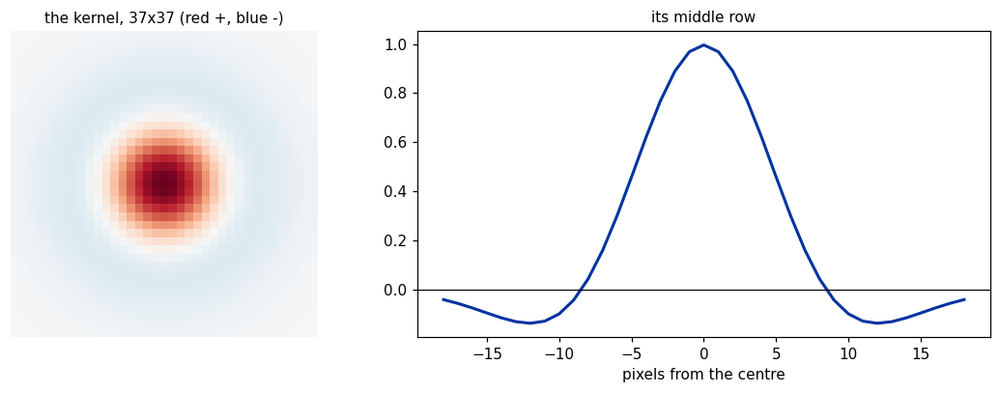

In [39]:
SIGMA = 6
r = 3 * SIGMA
yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
q = (xx ** 2 + yy ** 2) / (2 * SIGMA ** 2)
hat = (1 - q) * np.exp(-q)
hat -= hat.mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
lim = np.abs(hat).max()
axes[0].imshow(hat, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[0].set_title(f"the kernel, {hat.shape[0]}x{hat.shape[1]} (red +, blue -)", fontsize=10)
axes[0].axis("off")
axes[1].plot(np.arange(-r, r + 1), hat[r], color=BLUE, lw=2)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("pixels from the centre")
axes[1].set_title("its middle row", fontsize=10)
fig.tight_layout()
plt.show()

Slide it over the **darkness** of the crop (1 - gray: nuclei are darker than their
surroundings) with HW1b's convolution, and keep the spots where the response is a local maximum
and in its top 2%.

**Predict:** which nuclei will it find - the pale ones, the dark ones, or both?

76 matches in the crop


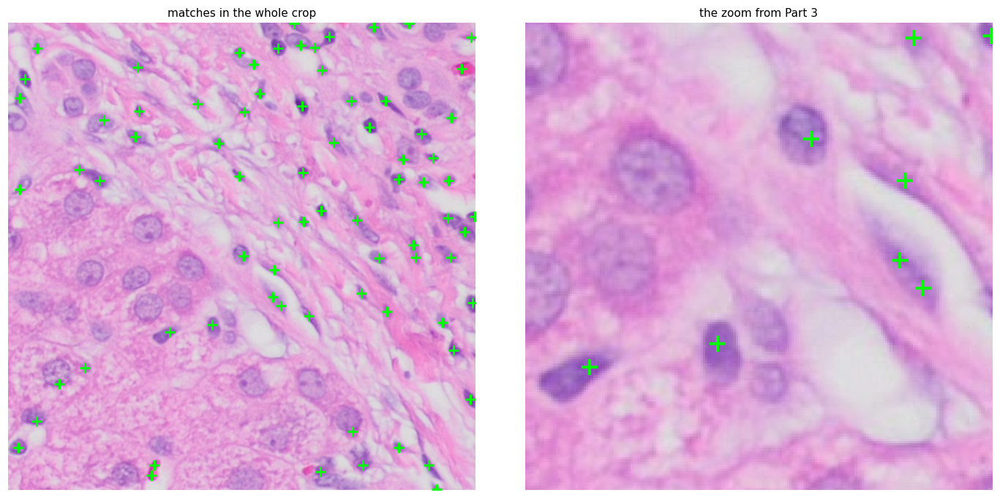

In [40]:
# ~12 s: a 37x37 kernel through the pure-NumPy tap loop
response = convolve2d_fast(1 - to_gray(HE), hat)
peaks = (response == ndimage.maximum_filter(response, size=2 * SIGMA + 1)) & (response > np.percentile(response, 98))
py, px = np.nonzero(peaks)
print(f"{len(px)} matches in the crop")
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
axes[0].imshow(HE)
axes[0].plot(px, py, "+", color="lime", ms=9, mew=2)
axes[0].set_title("matches in the whole crop", fontsize=10)
in_z = (py >= Z[0].start) & (py < Z[0].stop) & (px >= Z[1].start) & (px < Z[1].stop)
axes[1].imshow(HE[Z])
axes[1].plot(px[in_z] - Z[1].start, py[in_z] - Z[0].start, "+", color="lime", ms=14, mew=2.5)
axes[1].set_title("the zoom from Part 3", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

It finds the **dark scar nuclei** - and mostly only those. The pale liver-cell nuclei are barely
darker than their surroundings, so they score low and are missed. Two of its mistakes are
instructive:

- a long spindle-shaped nucleus gets **two** crosses: the template is round, so it matches the
  two ends of a long shape separately;
- it fires on **red blood cells** (the magenta blobs at the top right and near the bottom): dark
  in gray, so they look like nuclei to a kernel that sees only darkness. Colour, again.

One kernel, one size, one channel, weights from a formula. A CNN's first layer holds dozens of
kernels spanning all three colour channels, and picks their weights from labelled examples. That
is the next practical.